# Weekly demand forecasting on M5 (Walmart): walkthrough

This notebook is a short tour of the project. It

1. downloads and cleans the M5 data for one store (CA_1),
2. explains the forecasting target,
3. shows the leakage-safe backtest contract,
4. runs a **small** backtest (one department, two folds) so it finishes in a couple of minutes,
5. loads the results of the **full** run (`python -m demand_forecast.pipeline`), which covers all 3,049 items and 6 folds.

Everything lives in the `demand_forecast` package under `src/`; the notebook only calls it.

In [1]:
import pandas as pd
from IPython.display import Image, Markdown, display

from demand_forecast.backtest import TARGET, make_folds, run_backtest, split
from demand_forecast.data import load_weekly_panel
from demand_forecast.evaluation import annotate, fold_context, metrics_by_fold, summary_table
from demand_forecast.pipeline import default_models

pd.set_option("display.width", 140)
panel = load_weekly_panel("CA_1")  # downloads ~50 MB on first run, then cached
panel.head()

,series_id,week,sales,wm_yr_wk,dept_id,cat_id,store_id,sell_price,price_missing,discount,...,hol_MemorialDay,hol_IndependenceDay,hol_LaborDay,hol_Halloween,hol_Thanksgiving,hol_Christmas,hol_NewYear,is_holiday_week,holiday_next_week,holiday
0,FOODS_1_001,2011-01-29,10.0,11101,FOODS_1,FOODS,CA_1,2.0,0,0.0,...,0,0,0,0,0,0,0,0,1,
1,FOODS_1_001,2011-02-05,6.0,11102,FOODS_1,FOODS,CA_1,2.0,0,0.0,...,0,0,0,0,0,0,0,1,1,SuperBowl
2,FOODS_1_001,2011-02-12,10.0,11103,FOODS_1,FOODS,CA_1,2.0,0,0.0,...,0,0,0,0,0,0,0,1,0,ValentinesDay
3,FOODS_1_001,2011-02-19,13.0,11104,FOODS_1,FOODS,CA_1,2.0,0,0.0,...,0,0,0,0,0,0,0,0,0,
4,FOODS_1_001,2011-02-26,15.0,11105,FOODS_1,FOODS,CA_1,2.0,0,0.0,...,0,0,0,0,0,0,0,0,0,


## 1. Data and target

Each row is one **item in store CA_1 in one Walmart week** (Saturday to Friday). The target `sales` is the
number of units sold that week. Weekly item-level demand is what a store replenishment process actually
orders against, and it is hard: many items sell only a handful of units a week.

In [2]:
n_items = panel["series_id"].nunique()
weeks = panel["week"].agg(["min", "max", "nunique"])
item_mean = panel.groupby("series_id")["sales"].mean()
display(Markdown(
    f"**{n_items:,} items**, weeks {weeks['min']:%Y-%m-%d} to {weeks['max']:%Y-%m-%d} "
    f"({weeks['nunique']} weeks), {len(panel):,} item-weeks. "
    f"{(panel[TARGET] == 0).mean():.0%} of item-weeks have zero sales; "
    f"{(item_mean < 2).mean():.0%} of items average fewer than 2 units/week. "
    f"{panel['is_promo'].mean():.1%} of item-weeks are flagged as price promotions (proxy)."
))
panel.groupby("cat_id")[TARGET].describe()

**3,049 items**, weeks 2011-01-29 to 2016-05-14 (277 weeks), 683,167 item-weeks. 21% of item-weeks have zero sales; 18% of items average fewer than 2 units/week. 7.1% of item-weeks are flagged as price promotions (proxy).

,count,mean,std,min,25%,50%,75%,max
cat_id,,,,,,,,
FOODS,322481.0,16.942242,35.982276,0.0,2.0,8.0,17.0,2134.0
HOBBIES,126804.0,7.024368,14.779752,0.0,0.0,3.0,7.0,342.0
HOUSEHOLD,233882.0,6.267802,9.598186,0.0,1.0,3.0,8.0,240.0


In [3]:
ax = panel.groupby("week")[TARGET].sum().plot(figsize=(10, 3), title="CA_1: total units per week", color="#2a78d6")
ax.set_xlabel("");

## 2. The backtest contract

`make_folds` creates expanding-window folds whose 8-week test windows tile the end of the data. `split`
gives a model only the history up to the origin, and the test rows **with the target column removed**.
The tests in `tests/test_backtest.py` check this and also check that scrambling every future value leaves
every forecast unchanged.

In [4]:
folds = make_folds(panel["week"], n_folds=7, horizon=8)
pd.DataFrame([{"fold": f.fold, "train_end": f.train_end.date(), "test_start": f.test_weeks[0].date(),
               "test_end": f.test_weeks[-1].date()} for f in folds])

,fold,train_end,test_start,test_end
0,0,2015-04-18,2015-04-25,2015-06-13
1,1,2015-06-13,2015-06-20,2015-08-08
2,2,2015-08-08,2015-08-15,2015-10-03
3,3,2015-10-03,2015-10-10,2015-11-28
4,4,2015-11-28,2015-12-05,2016-01-23
5,5,2016-01-23,2016-01-30,2016-03-19
6,6,2016-03-19,2016-03-26,2016-05-14


In [5]:
history, future, actuals = split(panel, folds[-1])
assert history["week"].max() == folds[-1].train_end < future["week"].min()
assert TARGET not in future.columns
future.columns.tolist()

['series_id',
 'week',
 'horizon',
 'wm_yr_wk',
 'dept_id',
 'cat_id',
 'store_id',
 'sell_price',
 'price_missing',
 'discount',
 'is_promo',
 'n_events',
 'snap_days',
 'hol_SuperBowl',
 'hol_ValentinesDay',
 'hol_Easter',
 'hol_MemorialDay',
 'hol_IndependenceDay',
 'hol_LaborDay',
 'hol_Halloween',
 'hol_Thanksgiving',
 'hol_Christmas',
 'hol_NewYear',
 'is_holiday_week',
 'holiday_next_week',
 'holiday']

## 3. A small backtest you can rerun quickly

One department (FOODS_1, ~200 items), the last two folds, all four models. The numbers here are a
smoke test; the headline results come from the full run below.

In [6]:
small = panel[panel["dept_id"] == "FOODS_1"]
small_folds = folds[-2:]
fc = run_backtest(small, default_models(horizon=8), small_folds)
ctx = fold_context(small, small_folds)
small_metrics = metrics_by_fold(annotate(fc, small, ctx))
summary_table(small_metrics).round(3)

,MAE,RMSE,MASE,MAE vs seasonal naive,MASE min,MASE max,folds beating baseline (MASE)
model,,,,,,,
LightGBM,5.301,9.392,1.049,0.647,1.017,1.082,2/2
ETS,5.485,10.123,1.070,0.669,1.054,1.086,2/2
Moving average (8w),5.610,9.843,1.118,0.685,1.047,1.189,2/2
Seasonal naive,8.195,15.735,1.499,1.000,1.489,1.509,0/2


## 4. Full results (all 3,049 items, folds 1-6)

Produced by `python -m demand_forecast.pipeline --store CA_1` and saved in `reports/`.

In [7]:
summary = pd.read_csv("../reports/metrics_summary.csv", index_col=0)
summary.round(3)

,MAE,RMSE,MASE,MAE vs seasonal naive,MASE min,MASE max,folds beating baseline (MASE)
model,,,,,,,
LightGBM,4.129,9.039,0.963,0.633,0.914,1.027,6/6
ETS,4.330,10.042,0.996,0.664,0.949,1.038,6/6
Moving average (8w),4.562,10.958,1.027,0.700,0.978,1.067,6/6
Seasonal naive,6.531,14.606,1.437,1.000,1.373,1.506,0/6


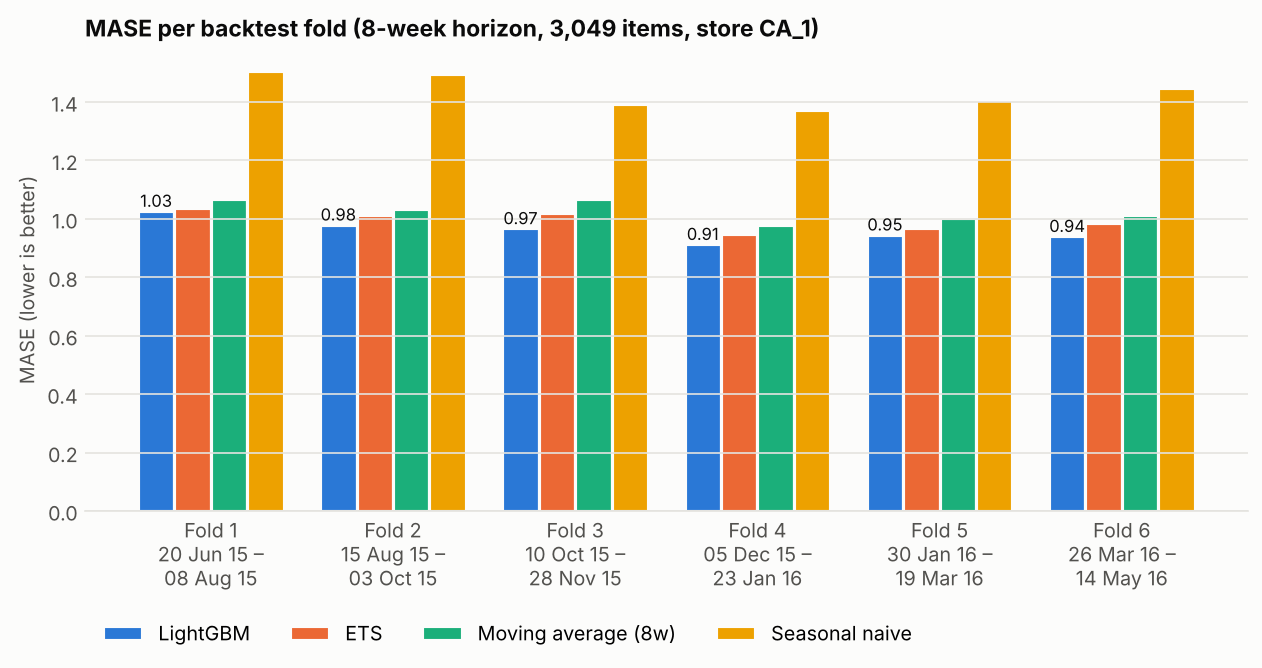

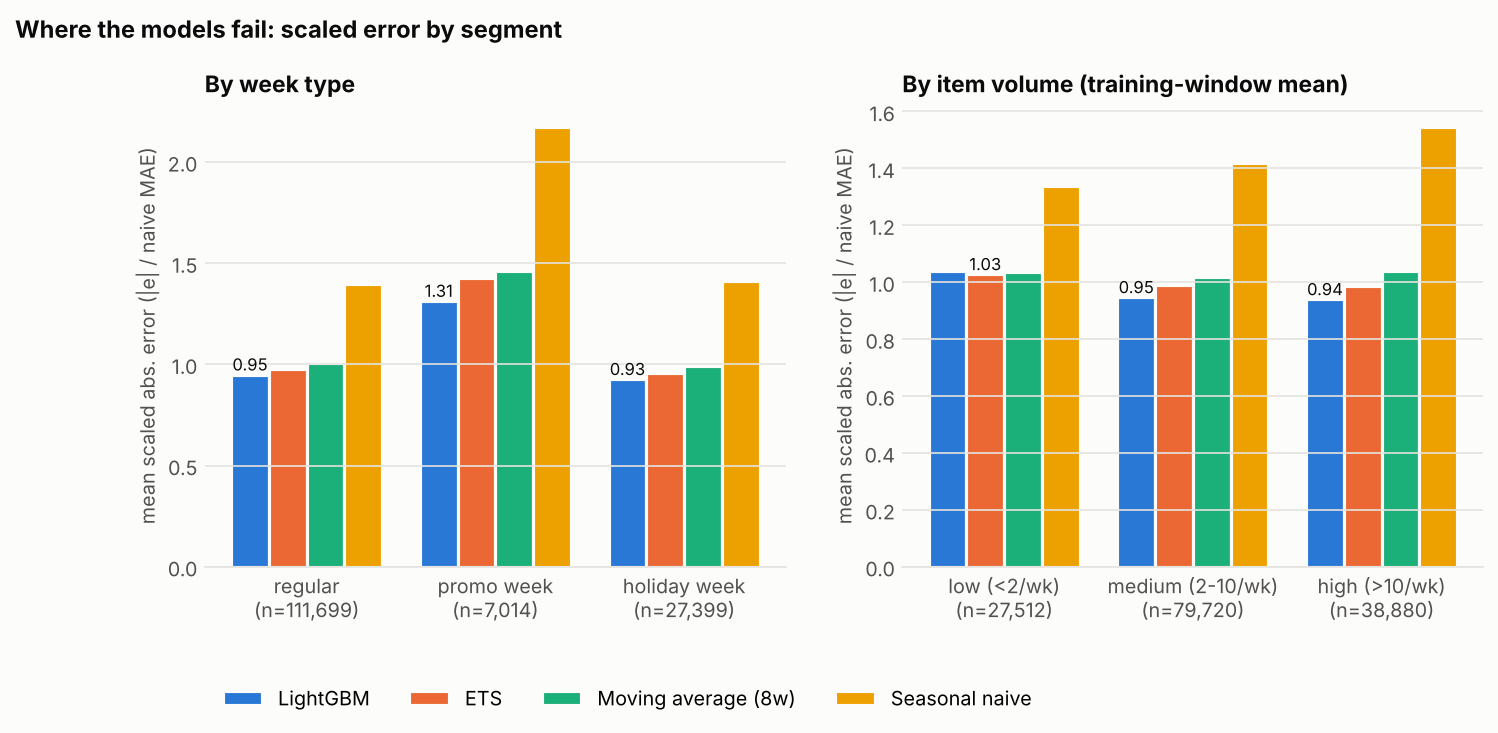

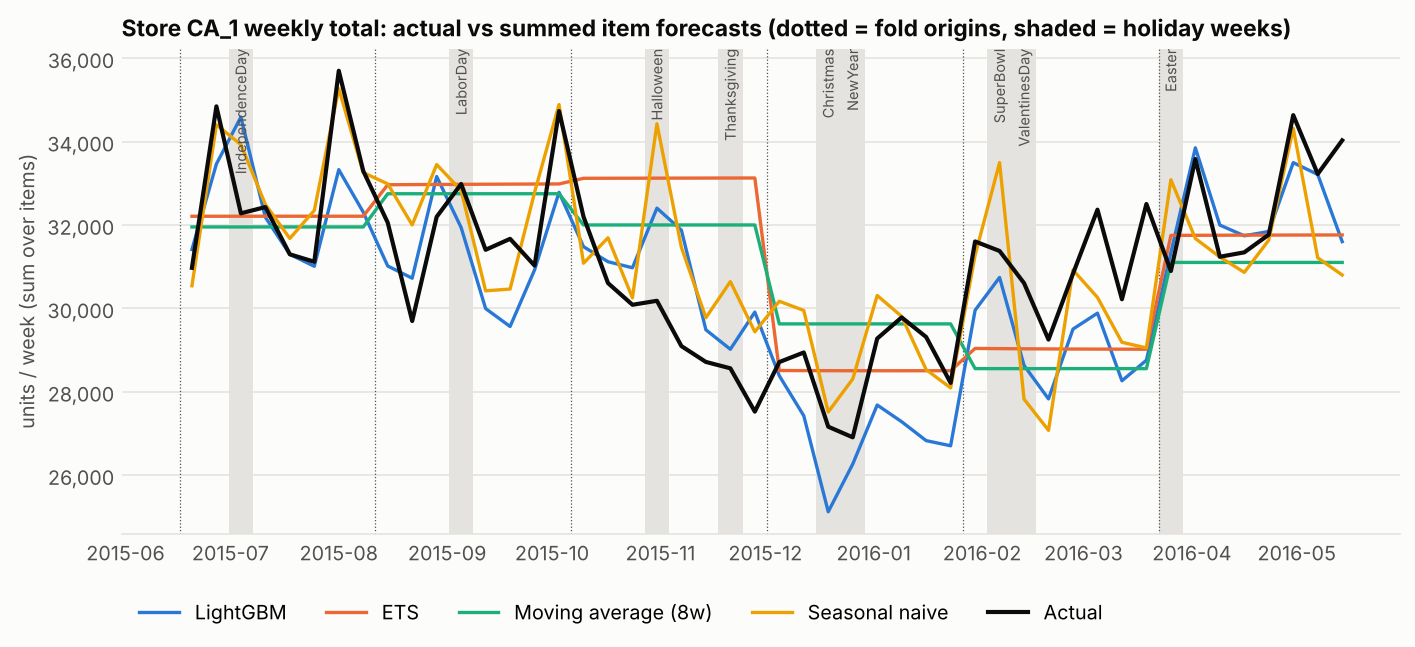

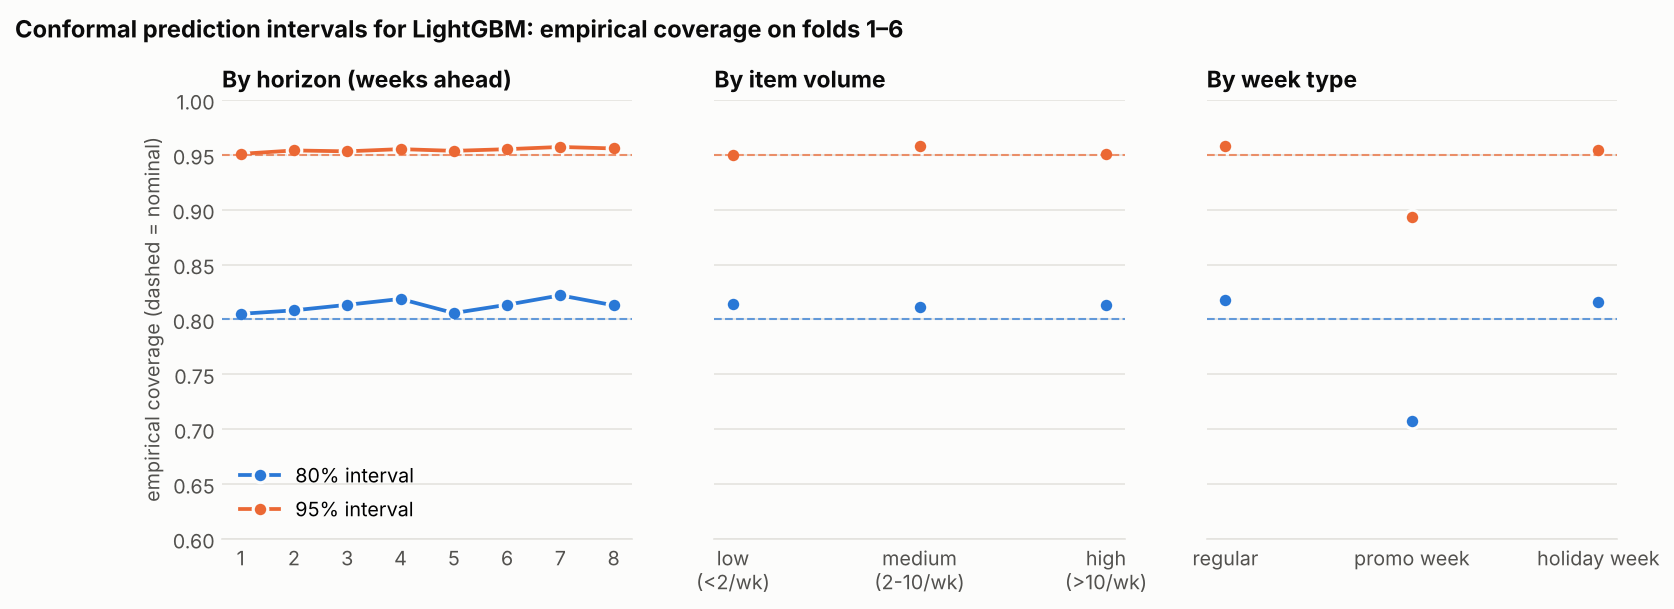

In [8]:
for fig in ["fold_mase", "segment_errors", "store_total", "interval_coverage"]:
    display(Image(f"../reports/figures/{fig}.png"))

See the README for the error analysis and the limitations of these results.